# Lab 8-02：回歸評估——改之前跑一次，改之後再跑一次

**目標**：用一份固定的 40 題題庫，替 mini RAG 的兩個改動（改 prompt、改 top_k）各跑一次評估，
跟基準版比，分數掉了就不准上線。最後把同一個規則寫成 pytest，讓 CI 自動擋。

**你會學到**
- 評估集＝驗證集：題目、參考答案、標籤，固定不動
- 一次「實驗」要存什麼：設定、每題結果、彙總分數
- 對比表、分標籤長條圖、找出「從 pass 變 fail」的題目
- 回歸閘門：程式化的上線門檻，以及 pytest 版

**前置**：Lab 8-01（`judge.py`）。這本會呼叫模型約 240 次，本機約 3～12 分鐘（看 GPU 有沒有被別的程式佔用）。

**對應投影片**：「評測流程」「評測的兩派觀點」「選型：評測工具」

![回歸評估閘門：固定題庫分別跑基準版與候選版，分數掉了就擋下](images/regression_gate.jpg)

*圖：題庫和 judge 都不動，只換受測系統；兩邊分數進同一個菱形閘門，掉分走朱紅色那條路被擋下。這就是深度學習裡「新 checkpoint 在驗證集上不能比舊的差」。原理見 `00_concepts.md` 第 4 節。*

## Step 1：看一眼題庫

`data/eval_set.jsonl` 有 40 題，每題有參考答案、正解文件 `doc_id`、標籤。
標籤讓你之後能分組看：數字題、條件題、換句話說的題目，以及 4 題「資料裡根本沒有」的題目。

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from course_utils.viz import setup_cjk
from judge import judge
from mini_rag import PROMPTS, MiniRAG, load_eval_set, load_faq

setup_cjk()

items = load_eval_set()
tags = pd.Series([t for it in items for t in it["tags"]]).value_counts()
print(tags.to_dict())
pd.DataFrame(items)[["id", "question", "reference", "tags"]].tail(6)

{'數字': 19, '條件': 12, '事實': 5, '改寫': 4, '無答案': 4}


,id,question,reference,tags
34,Q35,推薦朋友進來當工程師，獎金怎麼發？,"獎金 30,000 元，到職滿 3 個月發一半，滿 6 個月發另一半。",[數字]
35,Q36,結婚有禮金嗎？多少？,"有，結婚禮金 6,000 元。",[數字]
36,Q37,公司有提供員工宿舍嗎？,資料中沒有提到員工宿舍。,[無答案]
37,Q38,年終獎金通常發幾個月？,資料中沒有提到年終獎金。,[無答案]
38,Q39,可以帶寵物來辦公室嗎？,資料中沒有提到寵物規定。,[無答案]
39,Q40,育嬰假可以請多久？,資料中沒有提到育嬰假。,[無答案]


## Step 2：評估一個設定

一次評估＝對每一題：檢索 → 生成 → judge，再記下「檢索有沒有撈到正解文件」（Hit@k）。
結果連同設定一起存成 `runs/<名稱>.json`。存檔很重要：基準版跑一次就好，之後每個候選版都跟它比。

In [2]:
import time

RUNS = Path("runs")
RUNS.mkdir(exist_ok=True)
rag = MiniRAG(load_faq())


def run_eval(name: str, prompt: str = "v1", top_k: int = 3) -> pd.DataFrame:
    rows = []
    t0 = time.perf_counter()
    for it in items:
        out = rag.answer(it["question"], top_k=top_k, prompt=prompt)
        v = judge(it["question"], it["reference"], out["answer"])
        rows.append({
            "id": it["id"], "tags": it["tags"], "answer": out["answer"],
            "hit": it["doc_id"] is None or it["doc_id"] in out["retrieved"],
            "score": v["score"], "numbers_ok": v["numbers_ok"], "passed": v["passed"],
            "reason": v["reason"],
            "gen_tokens": out["prompt_tokens"] + out["completion_tokens"],
            "latency_ms": out["latency_ms"],
        })
    record = {"name": name, "config": {"prompt": prompt, "top_k": top_k}, "rows": rows}
    (RUNS / f"{name}.json").write_text(json.dumps(record, ensure_ascii=False, indent=1), encoding="utf-8")
    df = pd.DataFrame(rows)
    print(f"{name}：通過 {df['passed'].sum()}/{len(df)}，Hit@{top_k} {df['hit'].mean():.0%}，"
          f"{time.perf_counter() - t0:.0f} 秒")
    return df

## Step 3：跑基準版

基準版：prompt `v1`（只根據資料、沒有就說沒有、一到兩句），`top_k=3`。

In [3]:
print(PROMPTS["v1"])
base = run_eval("baseline", prompt="v1", top_k=3)

你是山嵐雲端的內部助理。只根據下面的「資料」回答同仁的問題，用一到兩句繁體中文直接回答。資料裡沒有的內容，就回答「資料中沒有提到」，不要猜。
baseline：通過 24/40，Hit@3 100%，81 秒


In [4]:
base[["id", "answer", "score", "numbers_ok", "passed"]].head(8)

,id,answer,score,numbers_ok,passed
0,Q01,特休要在人事系統「嵐葉」提前 3 個工作天申請。,3,True,False
1,Q02,資料中沒有提到,4,False,False
2,Q03,當年度沒休完的特休，最多可遞延 5 天到隔年 6 月底。,5,True,True
3,Q04,病假一年合計 30 天以內給半薪。,4,True,True
4,Q05,請了 3 天病假，診斷證明要在請假後 5 個工作天內上傳到「嵐葉」。,4,False,False
5,Q06,每位同仁每週最多遠端工作 2 天。,3,True,False
6,Q07,星期三不可以遠端。,5,True,True
7,Q08,遠端要在前一天 18:00 前於「嵐葉」登記。,5,True,True


基準版不會是 100%。把沒通過的題目印出來，分成兩種原因：

In [5]:
fails = base[~base["passed"]]
print(f"沒通過 {len(fails)} 題，其中數字規則沒過的 {(~fails['numbers_ok']).sum()} 題\n")
for r in fails.head(8).itertuples():
    print(f"{r.id} LLM {r.score} 分｜數字 {'對' if r.numbers_ok else '錯'}｜{r.answer[:40]}")
    print(f"     judge：{r.reason[:60]}")

沒通過 16 題，其中數字規則沒過的 7 題

Q01 LLM 3 分｜數字 對｜特休要在人事系統「嵐葉」提前 3 個工作天申請。
     judge：回答多寫了 '提前 3 個工作天申請'，漏了 '在「嵐葉」'，關鍵事實只對一半
Q02 LLM 4 分｜數字 錯｜資料中沒有提到
     judge：資料中提到需要部門主管與處長雙重簽核，但未提及特休的天數限制
Q05 LLM 4 分｜數字 錯｜請了 3 天病假，診斷證明要在請假後 5 個工作天內上傳到「嵐葉」。
     judge：關鍵事實對，但漏了請假後 5 個工作天內上傳到「嵐葉」這一點，回答多寫了內容
Q06 LLM 3 分｜數字 對｜每位同仁每週最多遠端工作 2 天。
     judge：回答多寫了 '每位同仁'，漏了 '每週'，關鍵事實只對一半
Q09 LLM 3 分｜數字 對｜VPN 出現 E-217 的意思是裝置憑證過期，需要到 IT 自助入口重新下載憑
     judge：回答了問題但沒有提到需要開單，缺少關鍵事實
Q13 LLM 5 分｜數字 錯｜資料中沒有提到
     judge：資料中提到台北市以外的縣市每晚上限 2,600 元
Q14 LLM 3 分｜數字 對｜出差的單據最晚要在出差結束後 30 天內上傳報帳系統。
     judge：關鍵事實對，但回答多寫了 '報帳系統'，漏了 '逾期不受理' 的細節
Q19 LLM 3 分｜數字 對｜不會，報名費另外全額補助，不佔 15,000 元額度。
     judge：關鍵事實對，但缺少 '與職務相關' 的細節，導致回答不完全準確


一種是系統真的答錯（例如明明資料有、卻回答「資料中沒有提到」）；另一種是**系統答對了，judge 太嚴**——
3B 評審常常挑字眼，說「少了『嵐葉』二字」就給 3 分。8-01 量到的 TPR 不高，指的就是這件事。

那這個 judge 還能用嗎？做回歸評估可以，因為基準版和候選版用的是**同一個** judge，比的是差值；
但要記得 judge 的雜訊會讓差值抖動 1～2 題，門檻要留一點容許值。回歸評估不要求滿分，它只問：**改了之後，有沒有比原本差？**

## Step 4：候選一——把 top_k 從 3 改成 1

動機很實際：塞進 prompt 的資料少三分之二，token 跟延遲都會下降。問題是品質會不會掉。

In [6]:
k1 = run_eval("top_k_1", prompt="v1", top_k=1)

top_k_1：通過 24/40，Hit@1 100%，38 秒


## Step 5：候選二——把 prompt 改得「更親切」

另一位同事覺得回答太冷淡，把 prompt 改成 `v2`：熱情、詳細、可以補充一般公司慣例。看起來是好意。

In [7]:
print(PROMPTS["v2"])
v2 = run_eval("prompt_v2", prompt="v2", top_k=3)

你是山嵐雲端熱情又貼心的內部助理。請盡量完整、詳細地幫同仁解答問題，可以補充你知道的一般公司慣例，讓同仁覺得被照顧。用繁體中文回答。
prompt_v2：通過 24/40，Hit@3 100%，269 秒


## Step 6：對比表

In [8]:
def summarize(df: pd.DataFrame) -> dict:
    no_ans = df[df["tags"].map(lambda t: "無答案" in t)]
    return {
        "通過率": df["passed"].mean(),
        "平均分數": df["score"].mean(),
        "Hit@k": df["hit"].mean(),
        "無答案題通過率": no_ans["passed"].mean(),
        "平均生成 token": df["gen_tokens"].mean(),
        "平均生成延遲 ms": df["latency_ms"].mean(),
    }


runs = {"基準版": base, "top_k=1": k1, "prompt v2": v2}
table = pd.DataFrame({name: summarize(df) for name, df in runs.items()}).T
table.style.format({"通過率": "{:.0%}", "Hit@k": "{:.0%}", "無答案題通過率": "{:.0%}",
                    "平均分數": "{:.2f}", "平均生成 token": "{:.0f}", "平均生成延遲 ms": "{:.0f}"})

,通過率,平均分數,Hit@k,無答案題通過率,平均生成 token,平均生成延遲 ms
基準版,60%,4.08,100%,100%,299,975
top_k=1,60%,4.12,100%,100%,164,366
prompt v2,60%,3.62,100%,50%,443,3817


## Step 7：分標籤長條圖

總分只是一個數字；分標籤看才知道**哪一類**題目退步。

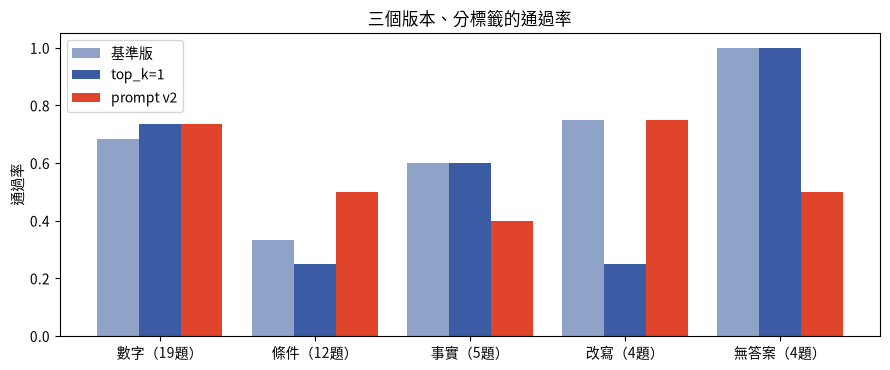

In [9]:
tag_names = ["數字", "條件", "事實", "改寫", "無答案"]


def pass_by_tag(df: pd.DataFrame) -> list[float]:
    return [df[df["tags"].map(lambda t: tag in t)]["passed"].mean() for tag in tag_names]


fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.27
colors = ["#8fa3c8", "#3b5ba5", "#e0442b"]
for i, (name, df) in enumerate(runs.items()):
    xs = [x + (i - 1) * width for x in range(len(tag_names))]
    ax.bar(xs, pass_by_tag(df), width, label=name, color=colors[i])
ax.set_xticks(range(len(tag_names)), [f"{t}（{tags[t]}題）" for t in tag_names])
ax.set_ylim(0, 1.05)
ax.set_ylabel("通過率")
ax.set_title("三個版本、分標籤的通過率")
ax.legend()
plt.tight_layout()
plt.show()

## Step 8：誰從 pass 變成 fail？

分數是給閘門看的；**變壞的那幾題**才是給工程師看的。把候選二退步的題目逐題印出來：

In [10]:
def flips(base_df: pd.DataFrame, cand_df: pd.DataFrame) -> pd.DataFrame:
    m = base_df.merge(cand_df, on="id", suffixes=("_base", "_cand"))
    return m[m["passed_base"] & ~m["passed_cand"]]


bad = flips(base, v2)
bad = bad.assign(no_ans=bad["tags_base"].map(lambda t: "無答案" in t)).sort_values("no_ans", ascending=False)
print(f"prompt v2：{len(bad)} 題從 pass 變 fail；top_k=1：{len(flips(base, k1))} 題\n")
question_of = {it["id"]: it["question"] for it in items}
for r in bad.head(5).itertuples():
    print(f"{r.id} {question_of[r.id]}")
    print(f"  基準版：{r.answer_base[:60]}")
    print(f"  v2   ：{r.answer_cand[:90]}")
    print(f"  judge：{r.reason_cand}\n")

prompt v2：9 題從 pass 變 fail；top_k=1：4 題

Q38 年終獎金通常發幾個月？
  基準版：資料中沒有提到
  v2   ：年終獎金通常在每年的十二月發放，具體發放時間可能會根據不同的公司政策有所不同。根據您提供的資料[F17]，我們可以看到內部推薦獎金的發放時間是被推薦人到職滿 3 個月發放一半，滿 
  judge：完全答非所問，或編造參考答案沒有的內容

Q40 育嬰假可以請多久？
  基準版：資料中沒有提到
  v2   ：根據您提供的資料，似乎並未明確列出育嬰假的相關規定。通常來說，育嬰假的長度會根據國家或地區的勞動法規定，並可能根據公司政策有所不同。在中國大陸，育嬰假的規定可能會因地區而異，但一般
  judge：回答了育嬰假的時間安排，但未提及資料中沒有提到育嬰假的關鍵事實

Q04 病假一年有幾天是半薪？
  基準版：病假一年合計 30 天以內給半薪。
  v2   ：根據您提供的資料[F02]，病假一年合計30天以內給半薪。因此，病假一年的半薪天數為30天。
  judge：回答了關鍵事實，但缺少了引用資料的細節，因此只對一半

Q10 VPN 密碼多久要換一次？
  基準版：VPN 密碼每 90 天要換一次。
  v2   ：根據您提供的[F04]條文，嵐通VPN的密碼需要每90天強制重設一次。如果您有其他問題或需要更多關於公司政策的資訊，請隨時告知。我會盡力提供幫助。
  judge：回答了與問題相關的內容，但關鍵事實漏了 '90 天'，語氣也與問題不符

Q16 忘記事前申請加班，可以事後補嗎？
  基準版：不可以，事後補申請一律退回。
  v2   ：根據您提供的資料[F07]，加班必須事前在「嵐葉」申請並經主管核准，事後補申請一律退回。因此，如果同仁忘記了加班申請，是無法在加班後再進行補申請的，必須在加班前就完成申請流程。


  judge：回答包含了關鍵事實，但對比參考答案有誤，關鍵事實只對一半



典型的退步樣子：資料裡沒有的題目（宿舍、年終、寵物、育嬰假），v2 開始「補充一般公司慣例」，等於編答案。
對使用者來說，這比「答不出來」更糟。

## Step 9：回歸閘門

把「不准上線」寫成程式。兩條規則：

1. 整體通過率不能比基準版低超過 2.5%（40 題裡容許 1 題，因為 judge 本身有雜訊）
2. 「無答案」題一題都不准退步：亂編答案是最不能接受的錯

In [11]:
TOLERANCE = 0.025


def gate(base_df: pd.DataFrame, cand_df: pd.DataFrame) -> tuple[bool, list[str]]:
    problems = []
    b, c = summarize(base_df), summarize(cand_df)
    if c["通過率"] < b["通過率"] - TOLERANCE:
        problems.append(f"整體通過率 {b['通過率']:.0%} → {c['通過率']:.0%}")
    if c["無答案題通過率"] < b["無答案題通過率"]:
        problems.append(f"無答案題通過率 {b['無答案題通過率']:.0%} → {c['無答案題通過率']:.0%}")
    return (not problems), problems


for name in ["top_k=1", "prompt v2"]:
    ok, problems = gate(base, runs[name])
    print(f"{name:10s} → {'可以上線' if ok else '擋下'}  {'；'.join(problems)}")

top_k=1    → 可以上線  
prompt v2  → 擋下  無答案題通過率 100% → 50%


注意 prompt v2 的**整體通過率**不一定比較低：它寫得長，常把參考答案的數字都帶到，judge 反而給高分。
只看總分的閘門會放它上線；是第二條「無答案題不准退步」把它擋下來的。這就是要按題型分別設門檻的原因。

如果 top_k=1 過了閘門，就是一個「品質不變、成本下降」的改動，可以上線，而且這句話本身就是一條好履歷（8-05 會用到）。
這份題庫的檢索太容易（bge-m3 幾乎每題第一名就撈到），所以 top_k=1 不太會傷品質；換成更難的題庫，結論可能不同。

## Step 10：pytest 版的閘門

同一套規則寫成 `test_regression.py`（就在本資料夾，打開來看只有幾十行），每條規則是一個 `assert`。
放進 CI 之後，任何人改 prompt 或參數，都要先過這關。這裡用 `subprocess` 對兩個候選版各跑一次：

In [12]:
import os
import subprocess
import sys

for cand in ["runs/top_k_1.json", "runs/prompt_v2.json"]:
    result = subprocess.run(
        [sys.executable, "-m", "pytest", "-q", "--no-header", "-p", "no:cacheprovider", "--color=no", "test_regression.py"],
        env={**os.environ, "CANDIDATE": cand}, capture_output=True, text=True,
    )
    print(f"===== CANDIDATE={cand}（exit code {result.returncode}）")
    lines = result.stdout.strip().splitlines()
    print("\n".join(l for l in lines if l.startswith(("E ", "FAILED", "PASSED")) or "passed" in l or "failed" in l))
    print()

===== CANDIDATE=runs/top_k_1.json（exit code 0）
3 passed in 0.01s

===== CANDIDATE=runs/prompt_v2.json（exit code 1）
E       AssertionError: 無答案題通過率 100% → 50%
E       assert 0.5 >= 1.0
FAILED test_regression.py::test_no_answer_questions_not_worse - AssertionErro...
1 failed, 2 passed in 0.03s



exit code 0 代表全部通過；非 0 時 CI 會把這次合併擋下來，`E` 開頭那幾行說明了哪條規則沒過。

## 試試看

1. 寫一個 `v3` prompt：保留 v2 的親切語氣，但加回「資料沒有就說資料中沒有提到」。跑 `run_eval("prompt_v3", prompt="v3")`，它過得了閘門嗎？（要先在 `mini_rag.PROMPTS` 加上 `"v3"`。）
2. 把 `TOLERANCE` 改成 0。閘門會不會因為 judge 的雜訊誤擋 top_k=1？容許值要怎麼訂比較合理？
3. 在 `test_regression.py` 加一條：平均生成 token 不能比基準版多 20% 以上。

## 小結

- 回歸評估＝固定題庫＋固定 judge＋存檔的基準結果；每次改動只換受測系統。
- 看總分決定能不能上線，看分標籤和「pass 變 fail」的題目決定怎麼修。
- 門檻寫成程式和 pytest，才擋得住「看起來是好意」的改動。下一本 8-03 用 Langfuse 替每一步打點，看時間和 token 花在哪。